In [1]:
import torch
import os
import sys

os.environ["GEOMSTATS_BACKEND"] = "pytorch"
os.environ["SCIPY_ARRAY_API"] = "1"

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

from xp_datasets import get_plot_kde_grassmann, plot_projections
from xp_datasets import annotate_outlier

sys.path.append("../")
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA
from lib_pca.utils_kde import kde_stiefel
from lib_pca.utils_sqrtm import sqrtm

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
import pandas as pd

data = pd.read_csv("data/Frogs_MFCCs.csv")
feature_columns = [column for column in data.columns if column.startswith("MFCCs_")]

name_families = sorted(data["Family"].unique())
name_genus = sorted(data["Genus"].unique())
# name_labels = sorted(data["Species"].unique())

concat_samples = torch.as_tensor(data[feature_columns].to_numpy(), dtype=torch.float64)

samples = []
labels = []

name_labels = name_families
for i, fam in enumerate(name_families):
    samples.append(torch.as_tensor(data[feature_columns][data["Family"] == fam].to_numpy(), dtype=torch.float64))
    labels += [i] * (data["Family"] == fam).sum()
labels = np.array(labels)

# name_labels = name_genus
# for i, gene in enumerate(name_genus):
#     samples.append(torch.as_tensor(data[feature_columns][data["Genus"] == gene].to_numpy(), dtype=torch.float64))
#     labels += [i] * (data["Genus"] == gene).sum()
# labels = np.array(labels)

weights_distrs = torch.tensor([len(samples[i])/len(concat_samples) for i in range(len(samples))], dtype=torch.float64)

n_classes = len(np.unique(labels))
d = len(feature_columns)

In [3]:
concat_samples.shape

torch.Size([7195, 22])

## PCA

In [4]:
## PCA

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(concat_samples.numpy())

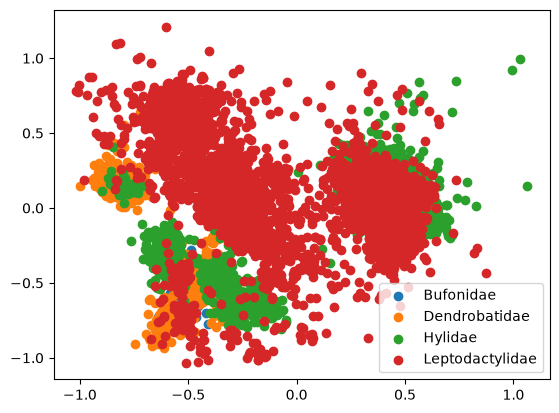

In [5]:
for k in range(n_classes):
    plt.scatter(X_reduced[labels==k, 0], X_reduced[labels==k, 1], label=name_labels[k])

plt.legend()
plt.show()

## UAPCA

In [6]:
# Distributional PCA
pca_distributional = UAPCA(2)
pca_distributional.fit_from_samples(samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()
print("Barycenter cost:", pca_distributional.cost_barycenter(samples).item())

INFO:2026-10-13 22:42:33,036:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


Barycenter cost: 0.2182706756177447


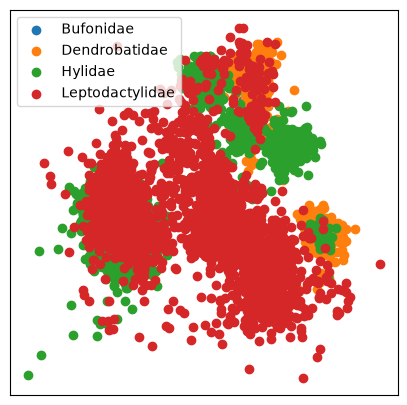

In [7]:
fig, ax = plt.subplots(
    nrows=1, 
    ncols=1,
    figsize=(5,5)
)

proj_points = torch.einsum("ij, ki -> kj", pca_distributional.components_, concat_samples).numpy()
for k in range(n_classes):
    ax.scatter(proj_points[labels == k, 0], proj_points[labels == k, 1], label=name_labels[k]) # , alpha=alpha[i*10+j])

ax.legend()

ax.set_xticks([])
ax.set_yticks([])

plt.show()

## Lifted PCA

In [8]:
lifted_pca = LiftedPCA(n_components=2, n_samples=100)
lifted_pca.fit(samples,  weights_distrs=weights_distrs)
eigenvectors_lifted = lifted_pca.components_

print("Barycenter cost:", lifted_pca.cost_barycenter(samples, weights_distrs=weights_distrs).item())

Barycenter cost: 0.06643983657142895


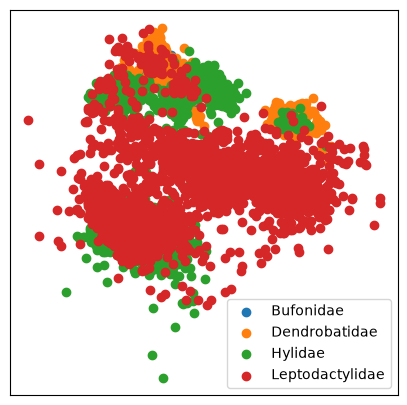

In [9]:
U_bary = lifted_pca.get_barycenter_components()

fig, ax = plt.subplots(
    nrows=1, 
    ncols=1,
    figsize=(5,5)
)

proj_points = torch.einsum("ij, ki -> kj", U_bary, concat_samples).numpy()
for k in range(n_classes):
    ax.scatter(proj_points[labels == k, 0], proj_points[labels == k, 1], label=name_labels[k]) # , alpha=alpha[i*10+j])

ax.legend()

ax.set_xticks([])
ax.set_yticks([])

plt.show()

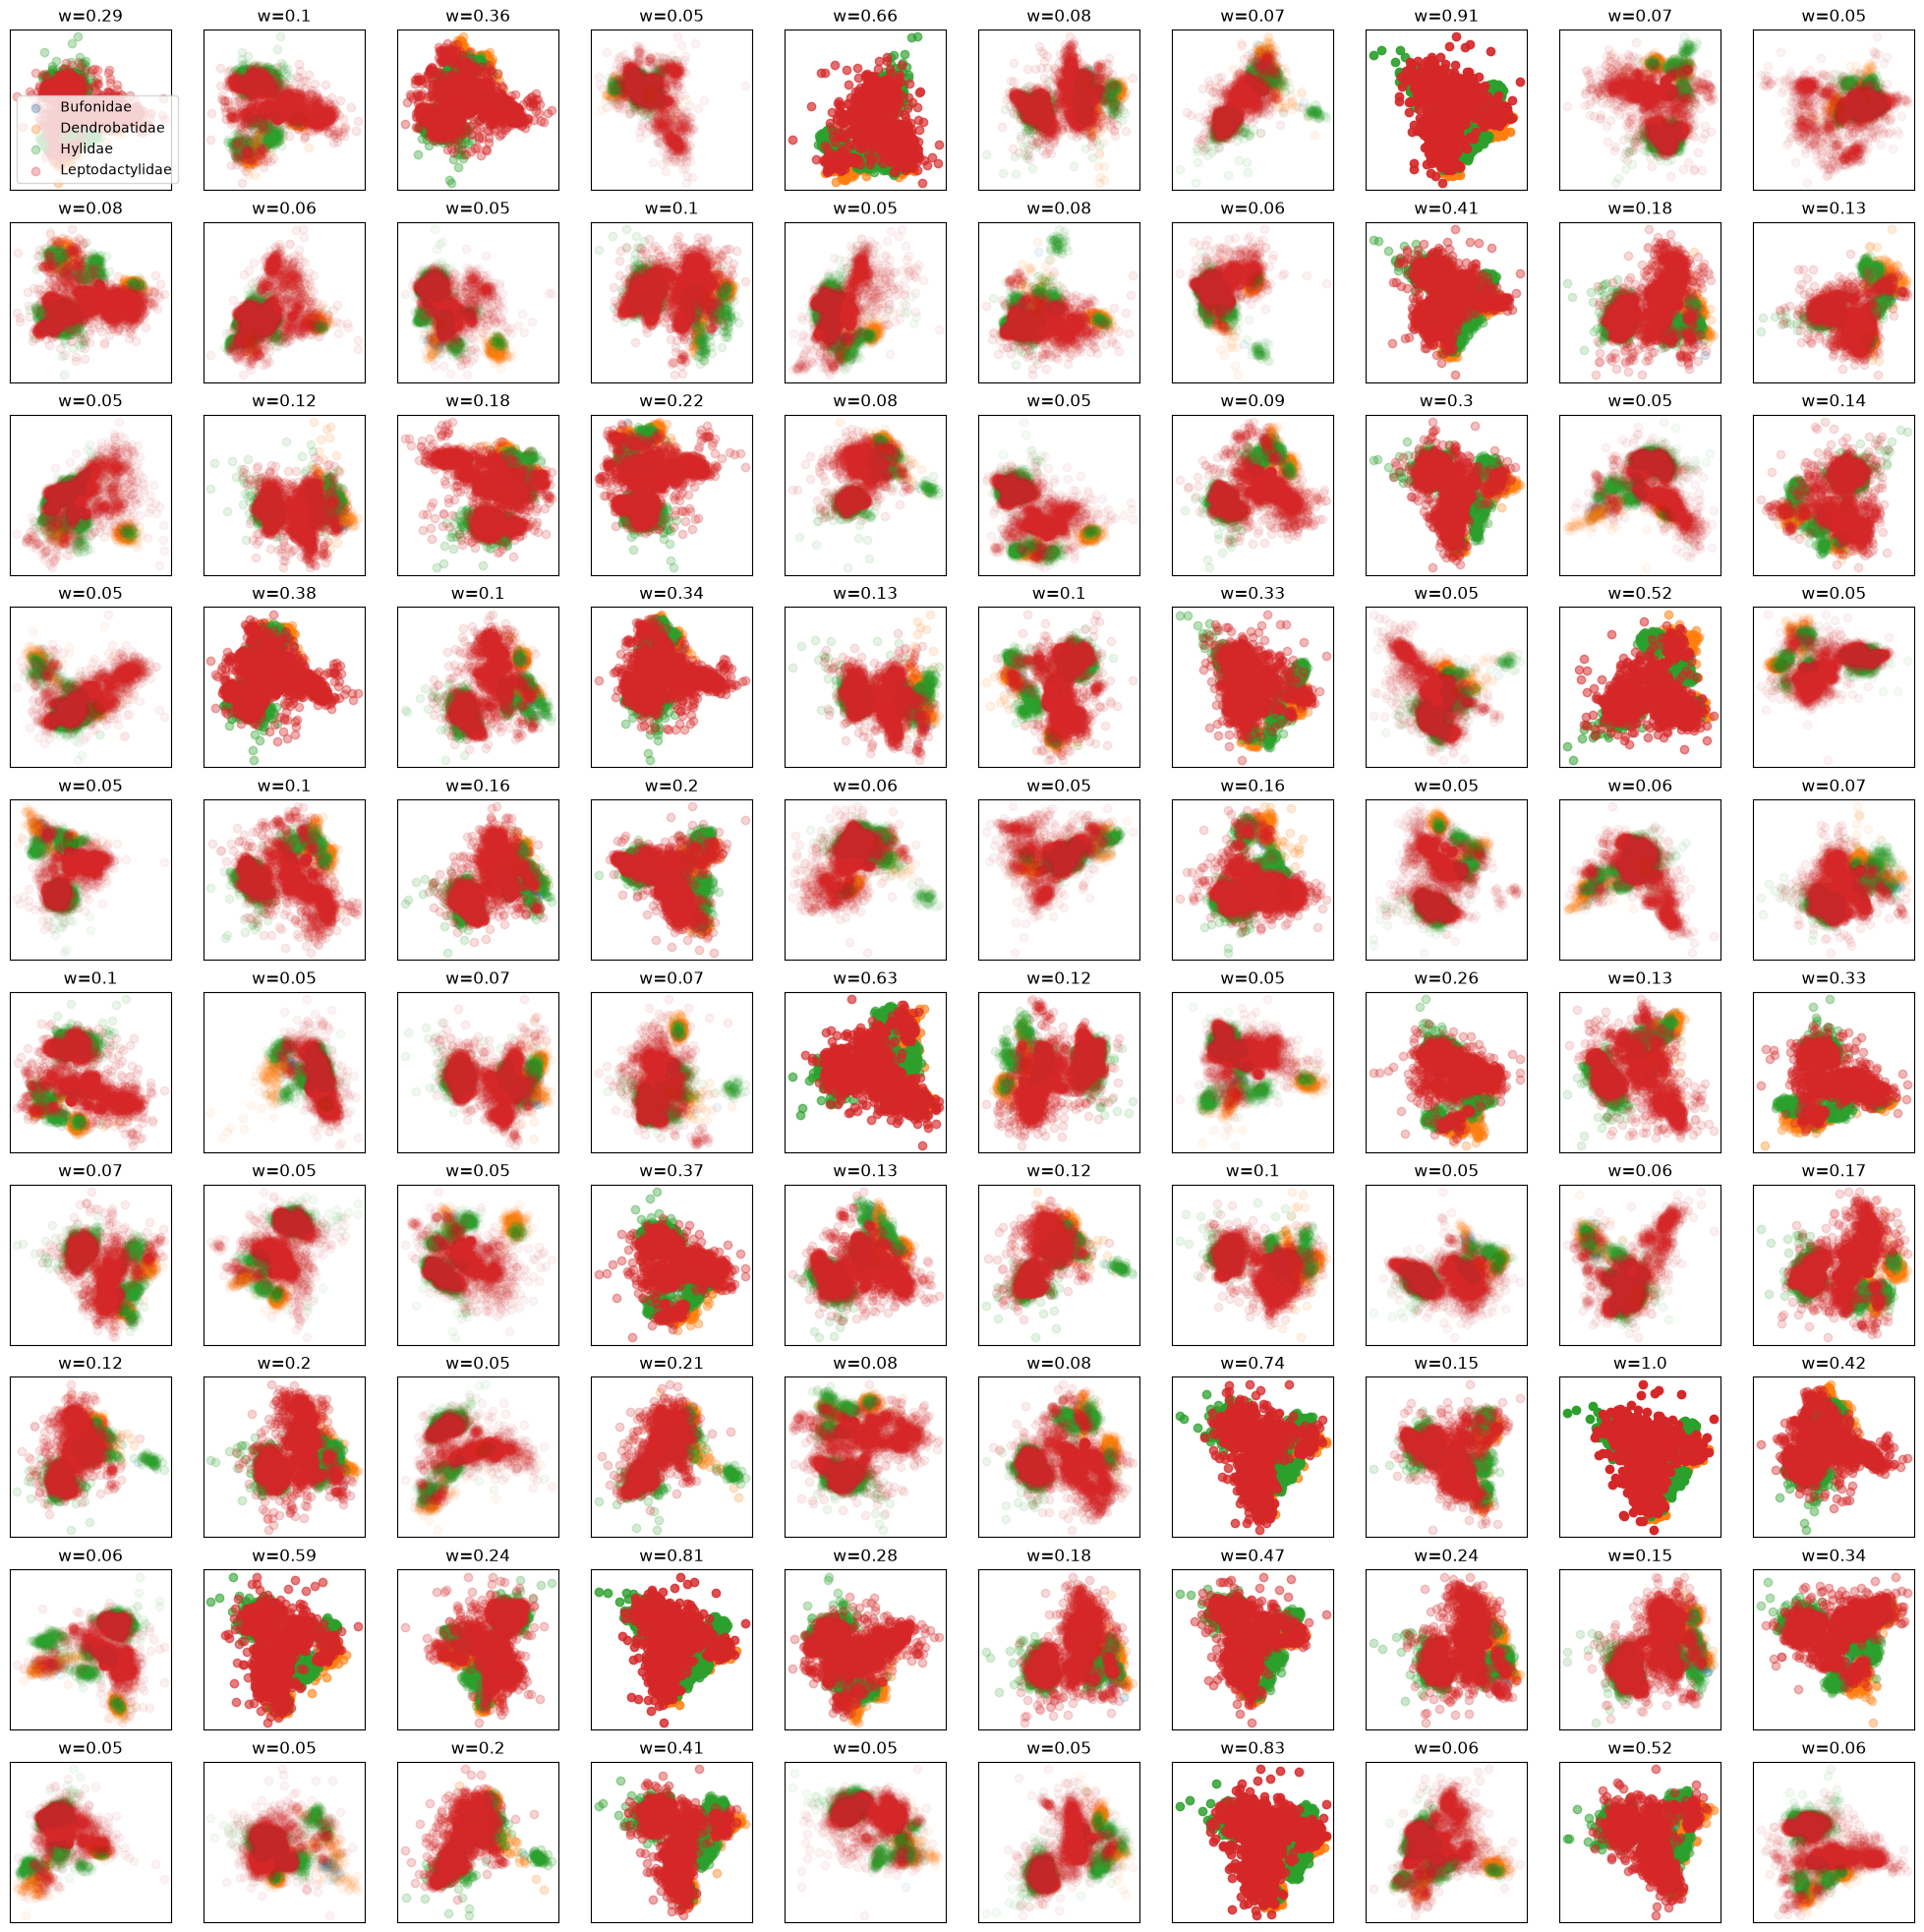

In [10]:
# weights = lifted_pca.weights_.numpy()
weights = kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25).numpy()
min_weights = weights.min()
max_weights = weights.max()
diff = max_weights - min_weights
alpha = 0.05 + 0.95 * (weights - min_weights) / diff

fig, axes = plt.subplots(
    nrows=10, 
    ncols=10,
    figsize=(25,25)
)

for i in range(10):
    for j in range(10):
        U = lifted_pca.components_[i*10+j]
        proj_points = torch.einsum("ij, ki -> kj", U, concat_samples).numpy()
        for k in range(n_classes):
            axes[i, j].scatter(proj_points[labels == k, 0], proj_points[labels == k, 1], label=name_labels[k] , alpha=alpha[i*10+j])

        if i == 0 and j == 0:
            axes[i, j].legend()

        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

        axes[i, j].set_title("w=" + str(round(alpha[i*10+j], 2)))

plt.show()

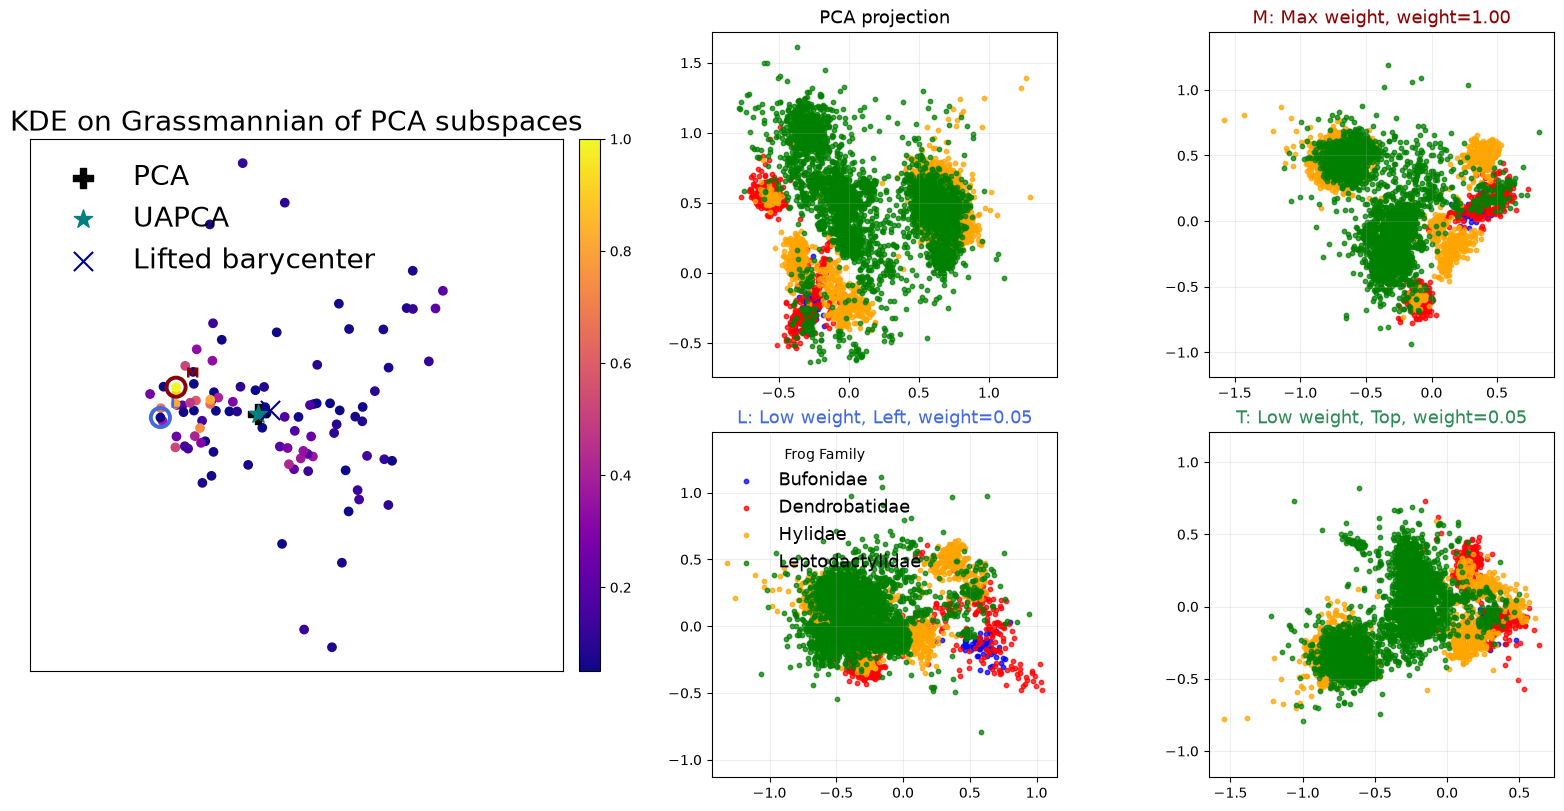

In [11]:
fig = plt.figure(figsize=(16, 8), constrained_layout=True)

outer_grid = fig.add_gridspec(1, 2, width_ratios=[1.35, 2.5])

projection_grid = outer_grid[1].subgridspec(2, 2)

ax_weights = fig.add_subplot(outer_grid[0])
ax_pca = fig.add_subplot(projection_grid[0, 0])
ax_barycenter = fig.add_subplot(projection_grid[0, 1])
ax_left_low = fig.add_subplot(projection_grid[1, 0])
ax_top_low = fig.add_subplot(projection_grid[1, 1])

pca_grassmann, alpha, alpha_bary = get_plot_kde_grassmann(
    lifted_pca, pca=pca_distributional, uapca=pca_distributional, title="KDE on Grassmannian of PCA subspaces", ax=ax_weights, fontsize=20
)

tangent_projected_data = pca_grassmann.transform(lifted_pca.components_).detach().cpu().numpy()

low_candidates = np.argsort(alpha)[:max(2, int(np.ceil(0.2 * len(alpha))))]
left_low_idx = int(low_candidates[np.argmin(tangent_projected_data[low_candidates, 0])])
top_candidates = low_candidates[low_candidates != left_low_idx]
top_low_idx = int(top_candidates[np.argmax(tangent_projected_data[top_candidates, 1])])

max_candidate = np.argmax(alpha)

annotate_outlier(ax_weights, tangent_projected_data[left_low_idx], marker_color="royalblue", label="L")
# annotate_outlier(ax_weights, tangent_projected_data[top_low_idx], marker_color="seagreen", label="T")
annotate_outlier(ax_weights, tangent_projected_data[max_candidate], marker_color="darkred", label="M")

proj_low = lifted_pca.components_[left_low_idx]
proj_top = lifted_pca.components_[top_low_idx]
proj_max = lifted_pca.components_[max_candidate]

alpha_low, alpha_top, alpha_bary, alpha_max = alpha[left_low_idx], alpha[top_low_idx], alpha_bary[0], alpha[max_candidate]

X_torch = concat_samples

class_colors = ["blue", "red", "orange", "green", "purple", "brown", "pink", "yellow"]

plot_projections(X_torch, torch.from_numpy(pca.components_.T), labels, name_labels, ax=ax_pca, s=10,
                 title="PCA projection", colors=class_colors)
# plot_projections(X_torch, lifted_pca.get_barycenter_components(), labels, name_labels, ax=ax_barycenter,
#                  title=f"LiftedPCA barycenter projection, weight={alpha_bary:.2f}", colors=class_colors)

plot_projections(X_torch, proj_low, labels, name_labels, ax=ax_left_low, s=10,
                 title=f"L: Low weight, Left, weight={alpha_low:.2f}", title_color="royalblue", colors=class_colors)

plot_projections(X_torch, proj_top, labels, name_labels, ax=ax_top_low, s=10,
                 title=f"T: Low weight, Top, weight={alpha_top:.2f}", title_color="seagreen", colors=class_colors)

plot_projections(X_torch, proj_max, labels, name_labels, ax=ax_barycenter, s=10,
                 title=f"M: Max weight, weight={alpha_max:.2f}", title_color="darkred", colors=class_colors)

ax_left_low.legend(title="Frog Family", frameon=False, fontsize=13, ncols=1)

# plt.savefig("./Figures/Results_anuran.pdf", format="pdf", bbox_inches="tight")
plt.show()